In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 4.0 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 4.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 4.6 MB/s  0:00:01 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 3.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 3.7 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [seaborn]4/16 [matplotlib]n]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [26]:
import sklearn
print(sklearn.__version__)

1.9.1


In [2]:

import os
import time
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("All libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [4]:

# Load Bank Marketing dataset

df = pd.read_csv(
    "bank-additional-full.csv",
    sep=";"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())


Number of rows: 41188
Number of columns: 21

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null 

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [6]:

# Check actual null values

print("Null values:")
display(df.isnull().sum())

# Check categorical unknown values

print("\nUnknown values in categorical columns:")

for col in df.select_dtypes(include="object").columns:
    count = (df[col] == "unknown").sum()

    if count > 0:
        print(f"{col}: {count}")


Null values:


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


Unknown values in categorical columns:
job: 330
marital: 80
education: 1731
default: 8597
housing: 990
loan: 990


In [7]:

print("Target class counts:")

display(df["y"].value_counts())

print("\nTarget distribution (%):")

display(
    (df["y"].value_counts(normalize=True) * 100).round(2)
)


Target class counts:


y
no     36548
yes     4640
Name: count, dtype: int64


Target distribution (%):


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

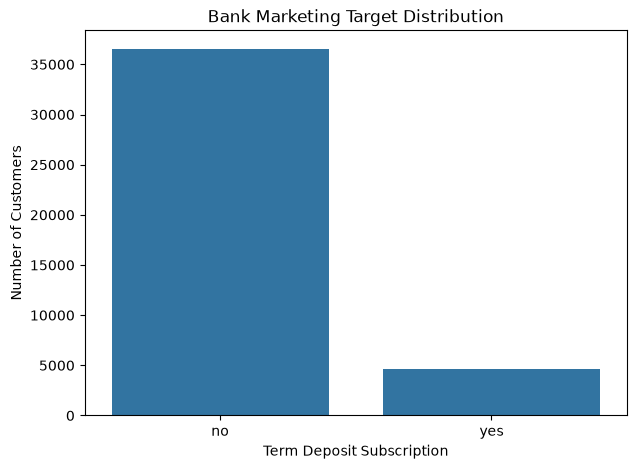

In [8]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y"
)

plt.title("Bank Marketing Target Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()


In [9]:

# Separate features and target

X = df.drop(
    columns=["y", "duration"]
)

y = df["y"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())


Feature shape: (41188, 19)
Target shape: (41188,)

Target classes:
<StringArray>
['no', 'yes']
Length: 2, dtype: str


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True))


Training samples: 32950
Testing samples: 8238

Training target distribution:


y
no     0.887344
yes    0.112656
Name: proportion, dtype: float64


Testing target distribution:


y
no     0.887351
yes    0.112649
Name: proportion, dtype: float64

In [11]:

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nNumber of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))


Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of numerical features: 9

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of categorical features: 10


In [12]:

# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
# Dense output is required by Gaussian Naive Bayes.

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])


# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [13]:

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbor": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": LinearSVC(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    )

}

print("All five classification models are defined!")


All five classification models are defined!


In [14]:

def evaluate_model(y_true, y_pred, y_score):

    y_true_binary = (y_true == "yes").astype(int)

    metrics = {
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "AUC": roc_auc_score(
            y_true_binary, y_score
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            pos_label="yes",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            pos_label="yes",
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            y_pred,
            pos_label="yes",
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        )
    }

    return metrics


In [15]:

results = []

trained_models = {}

predictions = {}

start_time = time.time()

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    model_start = time.time()

    # Create complete pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict class labels
    y_pred = pipeline.predict(X_test)

    # Get scores for positive class (yes)
    classifier = pipeline.named_steps["classifier"]

    if hasattr(classifier, "predict_proba"):

        probabilities = pipeline.predict_proba(X_test)

        yes_index = list(classifier.classes_).index("yes")

        y_score = probabilities[:, yes_index]

    else:

        y_score = pipeline.decision_function(X_test)

        # In binary classification, positive decision scores
        # correspond to the second class in classes_
        if list(classifier.classes_).index("yes") == 0:
            y_score = -y_score

    # Calculate metrics
    metrics = evaluate_model(
        y_test,
        y_pred,
        y_score
    )

    metrics["Model"] = name

    results.append(metrics)

    trained_models[name] = pipeline

    predictions[name] = y_pred

    model_time = time.time() - model_start

    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("AUC:", round(metrics["AUC"], 4))
    print("Precision:", round(metrics["Precision"], 4))
    print("Recall:", round(metrics["Recall"], 4))
    print("F1:", round(metrics["F1"], 4))
    print("MCC:", round(metrics["MCC"], 4))

    print("Execution time:", round(model_time, 2), "seconds")


total_time = time.time() - start_time

print("\nAll models trained successfully!")
print("Total execution time:", round(total_time, 2), "seconds")



Training: Logistic Regression
Accuracy: 0.835
AUC: 0.8009
Precision: 0.3679
Recall: 0.6466
F1: 0.4689
MCC: 0.4011
Execution time: 0.23 seconds

Training: Decision Tree
Accuracy: 0.8468
AUC: 0.6234
Precision: 0.3249
Recall: 0.3341
F1: 0.3294
MCC: 0.243
Execution time: 0.29 seconds

Training: K-Nearest Neighbor
Accuracy: 0.8972
AUC: 0.7439
Precision: 0.5835
Recall: 0.305
F1: 0.4006
MCC: 0.3725
Execution time: 0.56 seconds

Training: Naive Bayes
Accuracy: 0.8049
AUC: 0.7755
Precision: 0.3172
Recall: 0.6347
F1: 0.423
MCC: 0.349
Execution time: 0.15 seconds

Training: Support Vector Machine
Accuracy: 0.8331
AUC: 0.8007
Precision: 0.3641
Recall: 0.6455
F1: 0.4656
MCC: 0.3973
Execution time: 0.26 seconds

All models trained successfully!
Total execution time: 1.5 seconds


In [17]:
# Create comparison table

results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1",
        "MCC"
    ]
]

results_df = results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

# Round metric values to 4 decimal places
results_df = results_df.round(4)

display(results_df)


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8350,0.8009,0.3679,0.6466,0.4689,0.4011
1,Support Vector Machine,0.8331,0.8007,0.3641,0.6455,0.4656,0.3973
2,Naive Bayes,0.8049,0.7755,0.3172,0.6347,0.4230,0.3490
3,K-Nearest Neighbor,0.8972,0.7439,0.5835,0.3050,0.4006,0.3725
4,Decision Tree,0.8468,0.6234,0.3249,0.3341,0.3294,0.2430


In [25]:
print(results_df.columns.tolist())

['Model', 'Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']


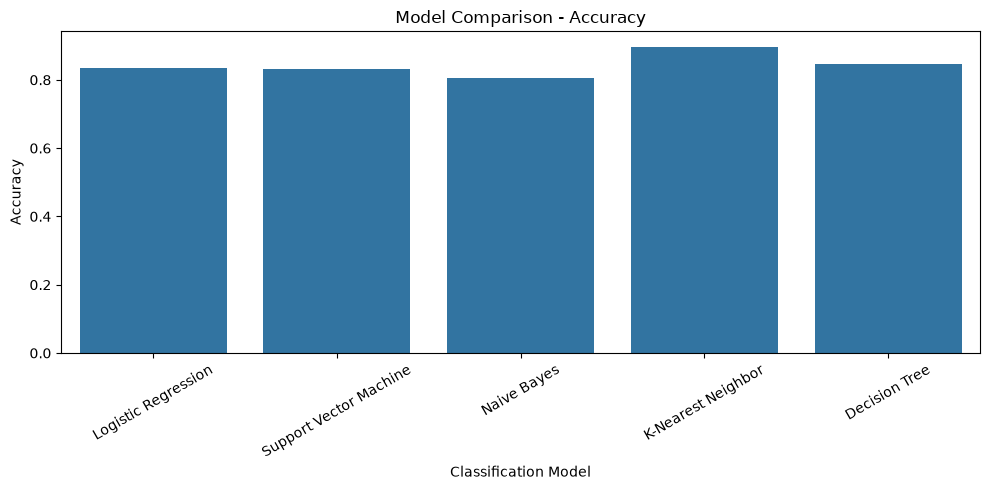

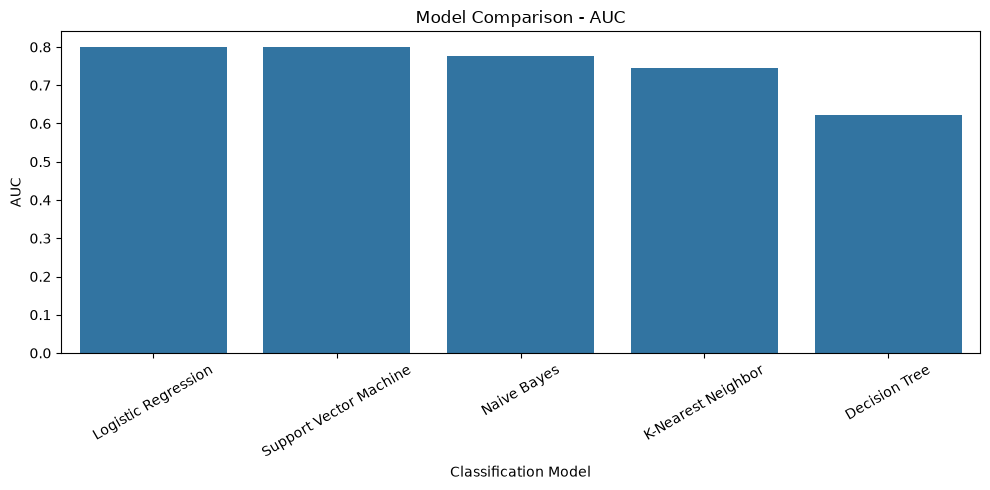

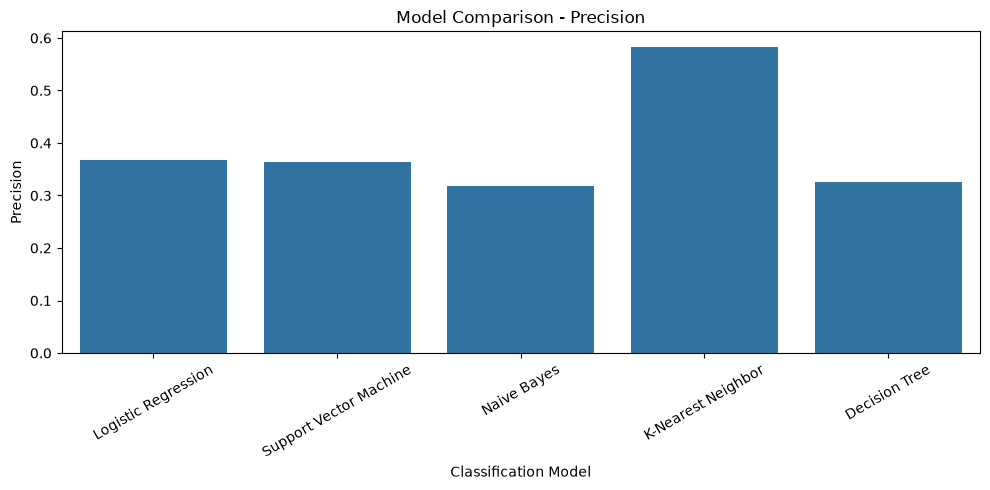

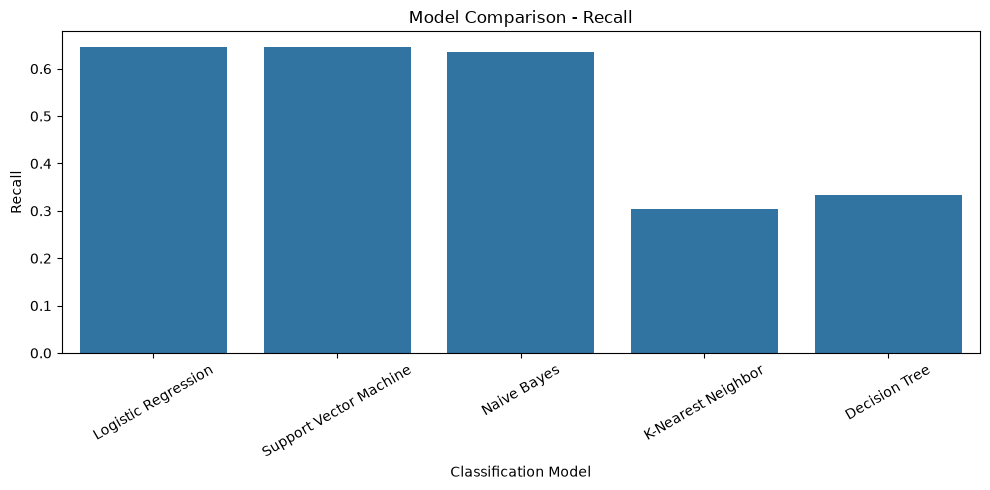

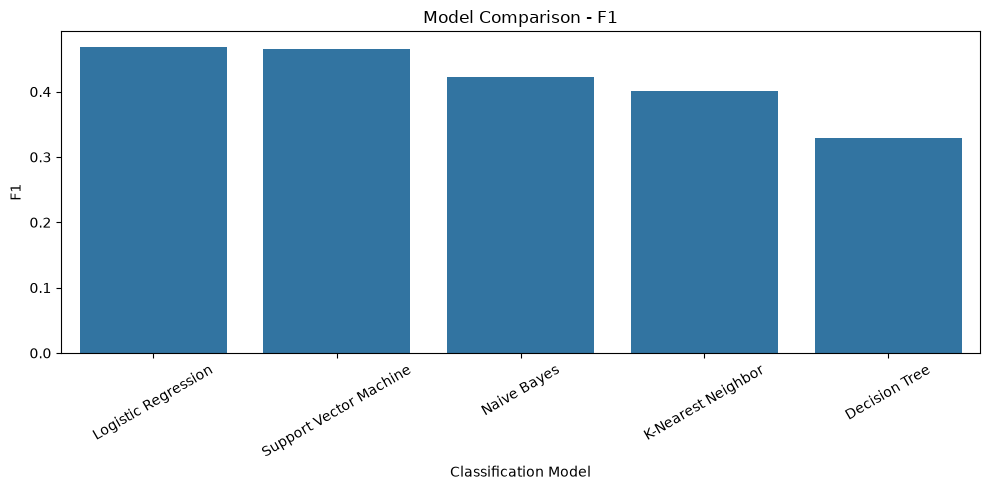

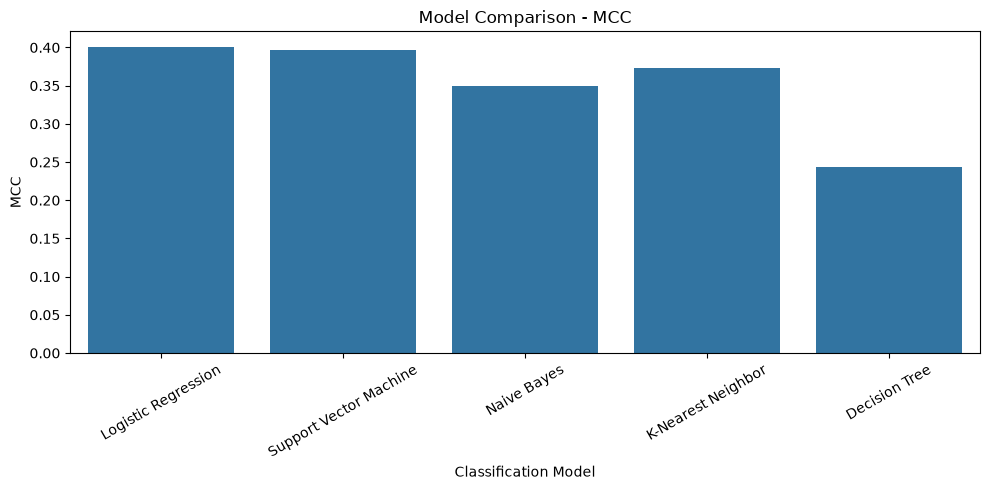

In [18]:

metrics_to_plot = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=30)
    plt.ylabel(metric)
    plt.xlabel("Classification Model")

    plt.tight_layout()
    plt.show()


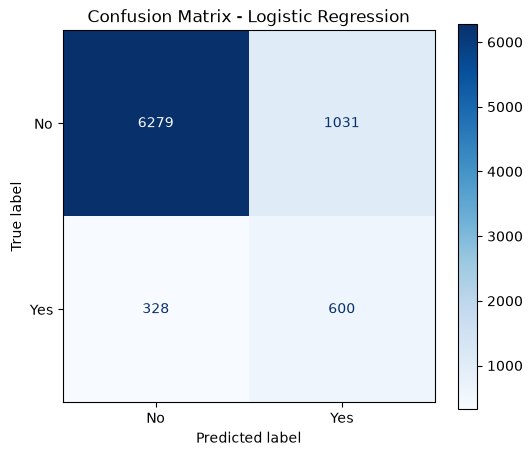

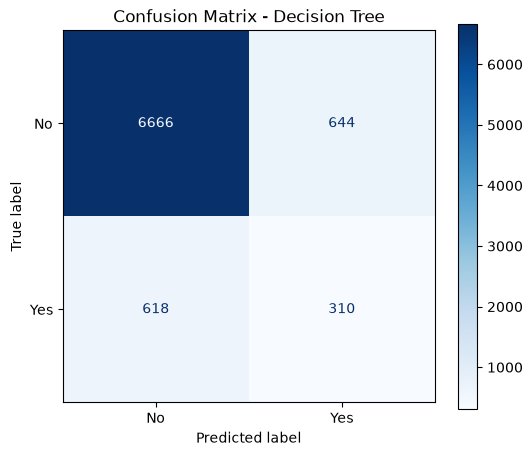

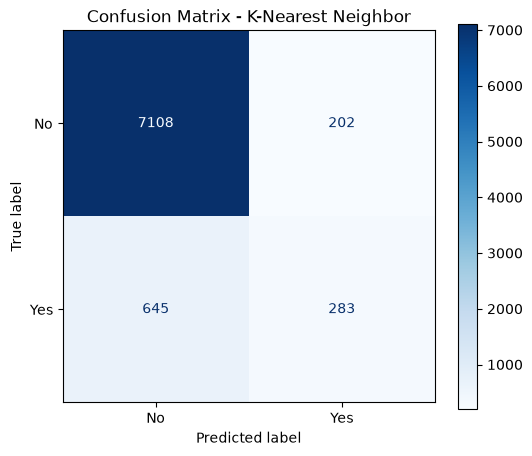

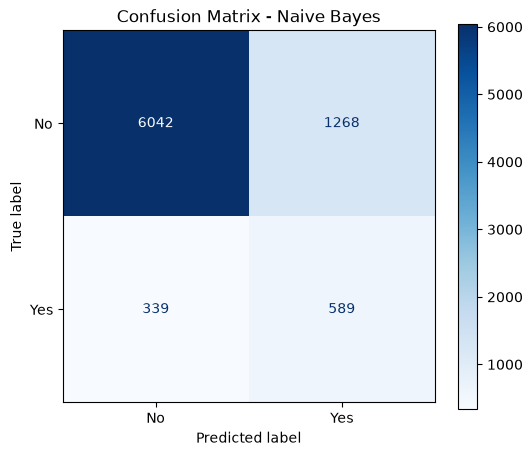

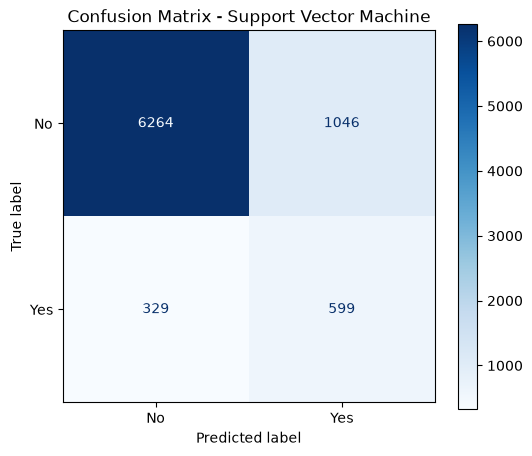

In [19]:

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["no", "yes"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()


In [20]:

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print("Classification Report:", name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=["no", "yes"],
            zero_division=0
        )
    )



Classification Report: Logistic Regression
              precision    recall  f1-score   support

          no       0.95      0.86      0.90      7310
         yes       0.37      0.65      0.47       928

    accuracy                           0.84      8238
   macro avg       0.66      0.75      0.69      8238
weighted avg       0.88      0.84      0.85      8238


Classification Report: Decision Tree
              precision    recall  f1-score   support

          no       0.92      0.91      0.91      7310
         yes       0.32      0.33      0.33       928

    accuracy                           0.85      8238
   macro avg       0.62      0.62      0.62      8238
weighted avg       0.85      0.85      0.85      8238


Classification Report: K-Nearest Neighbor
              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7310
         yes       0.58      0.30      0.40       928

    accuracy                           0.90      8238
   

In [21]:

os.makedirs("model", exist_ok=True)

model_file_names = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "K-Nearest Neighbor": "knn.pkl",
    "Naive Bayes": "naive_bayes.pkl",
    "Support Vector Machine": "svm.pkl"
}

for name, pipeline in trained_models.items():

    filepath = os.path.join(
        "model",
        model_file_names[name]
    )

    joblib.dump(
        pipeline,
        filepath
    )

    print("Saved:", filepath)

print("\nAll five models saved successfully!")


Saved: model/logistic_regression.pkl
Saved: model/decision_tree.pkl
Saved: model/knn.pkl
Saved: model/naive_bayes.pkl
Saved: model/svm.pkl

All five models saved successfully!


In [22]:

test_data = X_test.copy()

test_data["y"] = y_test.values

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved successfully!")

print("Test data shape:", test_data.shape)

display(test_data.head())


Test dataset saved successfully!
Test data shape: (8238, 20)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
14455,32,management,divorced,university.degree,no,no,no,cellular,jul,tue,5,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,no
36380,37,unemployed,unknown,university.degree,no,no,no,cellular,jun,tue,1,999,0,nonexistent,-2.9,92.963,-40.8,1.262,5076.2,no
40076,73,retired,divorced,professional.course,unknown,yes,no,cellular,jul,thu,2,999,0,nonexistent,-1.7,94.215,-40.3,0.810,4991.6,no
10778,44,entrepreneur,married,basic.4y,unknown,no,no,telephone,jun,tue,2,999,0,nonexistent,1.4,94.465,-41.8,4.961,5228.1,no
27939,28,admin.,single,high.school,no,no,no,cellular,mar,fri,2,999,0,nonexistent,-1.8,92.843,-50.0,1.531,5099.1,no


In [23]:

results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved!")


Model comparison results saved!


In [24]:

print("=" * 60)
print("BANK MARKETING CLASSIFICATION PROJECT")
print("=" * 60)

print("Dataset:", "Bank Marketing Additional")
print("Total instances:", len(df))
print("Features used:", X.shape[1])
print("Training instances:", len(X_train))
print("Testing instances:", len(X_test))
print("Models implemented:", len(trained_models))

print("\nBest model based on F1 Score:")

best_model = results_df.iloc[0]

print("Model:", best_model["Model"])
print("F1 Score:", round(best_model["F1"], 4))
print("Accuracy:", round(best_model["Accuracy"], 4))
print("AUC:", round(best_model["AUC"], 4))

print("\nProject execution completed!")


BANK MARKETING CLASSIFICATION PROJECT
Dataset: Bank Marketing Additional
Total instances: 41188
Features used: 19
Training instances: 32950
Testing instances: 8238
Models implemented: 5

Best model based on F1 Score:
Model: Logistic Regression
F1 Score: 0.4689
Accuracy: 0.835
AUC: 0.8009

Project execution completed!
